Author:  
Manuel Eugenio Morocho Cayamcela, PhD

## Exploratory Data Analysis of the Titanic Dataset

The Titanic was a famous ocean liner that tragically sank on its maiden voyage in 1912. Considered at the time the largest and most luxurious ship in the world, it was a symbol of the opulence and technological progress of the era.

On April 10, 1912, the Titanic departed from Southampton, England, bound for New York. However, on the night of April 14–15, the ship struck an iceberg in the North Atlantic and sank within hours. The disaster killed more than 1,500 people, making it one of the deadliest maritime tragedies in history.

### Introduction

This activity introduces basic exploratory data analysis using pandas and data visualization. We will inspect the dataset's structure, review descriptive statistics, check for missing values, and use plots to assess the hypotheses below.

The dataset is hosted in this GitHub repository, so you do not need to download or share it separately.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/eugeniomorocho/ArtificialIntelligence/main/Datasets/titanic.csv"
try:
    df = pd.read_csv(url)
except Exception:
    # Fallback: local copy of the same file (in the same folder as this notebook)
    df = pd.read_csv("titanic.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Each row represents one passenger, and each column records a passenger attribute.

The dataset contains these columns:

1. `PassengerId`: Unique passenger identifier.
2. `Survived`: Survival status (0 = no, 1 = yes).
3. `Pclass`: Ticket class (1 = first, 2 = second, 3 = third).
4. `Name`: Passenger's name.
5. `Sex`: Passenger's sex.
6. `Age`: Passenger's age.
7. `SibSp`: Number of siblings or spouses aboard.
8. `Parch`: Number of parents or children aboard.
9. `Ticket`: Ticket number.
10. `Fare`: Ticket fare.
11. `Cabin`: Cabin number.
12. `Embarked`: Port of embarkation (C = Cherbourg, Q = Queenstown, S = Southampton).

### Dataset Inspection

In the code cell below, display the dataset dimensions, data types, missing-value counts, and descriptive statistics. Keep the outputs visible. Then use the Markdown cell to identify which columns have missing values and describe one observation from the statistics.

In [2]:
# Inspect the dataset: dimensions, data types, missing values, and descriptive statistics.

# 1. Dimensions
print("Dimensions (rows, columns):", df.shape)

# 2. Data types
print("\nData types:")
print(df.dtypes)

# 3. Missing values (count and percentage)
missing = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_pct": (df.isnull().mean() * 100).round(2)
})
print("\nMissing values per column:")
print(missing)

# 4. Descriptive statistics
print("\nDescriptive statistics (numeric columns):")
display(df.describe().round(2))

print("Descriptive statistics (categorical columns):")
display(df.select_dtypes(exclude="number").describe())

Dimensions (rows, columns): (891, 12)

Data types:
PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

Missing values per column:
             missing_count  missing_pct
PassengerId              0         0.00
Survived                 0         0.00
Pclass                   0         0.00
Name                     0         0.00
Sex                      0         0.00
Age                    177        19.87
SibSp                    0         0.00
Parch                    0         0.00
Ticket                   0         0.00
Fare                     0         0.00
Cabin                  687        77.10
Embarked                 2         0.22

Descriptive statistics (numeric columns):


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.00,891.00,891.00,714.00,891.00,891.00,891.00
mean,446.00,0.38,2.31,29.70,0.52,0.38,32.20
std,257.35,0.49,0.84,14.53,1.10,0.81,49.69
min,1.00,0.00,1.00,0.42,0.00,0.00,0.00
25%,223.50,0.00,2.00,20.12,0.00,0.00,7.91
50%,446.00,0.00,3.00,28.00,0.00,0.00,14.45
75%,668.50,1.00,3.00,38.00,1.00,0.00,31.00
max,891.00,1.00,3.00,80.00,8.00,6.00,512.33


Descriptive statistics (categorical columns):


,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


**Inspection notes:** Summarize what you found in the inspection and whether any preprocessing is needed for the hypotheses below.

- **Size:** the dataset has **891 rows (passengers) and 12 columns**. There are 5 integer columns (`PassengerId`, `Survived`, `Pclass`, `SibSp`, `Parch`), 2 float columns (`Age`, `Fare`) and 5 text columns (`Name`, `Sex`, `Ticket`, `Cabin`, `Embarked`).
- **Columns with missing values:**
  - `Cabin`: 687 missing (≈77.1%) — most passengers have no recorded cabin.
  - `Age`: 177 missing (≈19.9%).
  - `Embarked`: 2 missing (≈0.2%).
  - All other columns are complete.
- **Observation from the statistics:** the mean of `Survived` is **0.38**, so only about **38% of passengers survived** (342 out of 891). Another notable point is `Fare`: the mean (32.20) is more than twice the median (14.45) and the maximum reaches 512.33, so fares are strongly right-skewed — a few very expensive tickets (mostly first class) pull the average up. Also, the median of `Pclass` is 3, meaning at least half of the passengers travelled in third class.
- **Is preprocessing needed?** Not for these two hypotheses. They only use `Survived`, `Sex` and `Pclass`, and these three columns have **no missing values** and are already in a usable format (`Survived` is 0/1, so its mean is directly the survival rate). The missing values in `Age`, `Cabin` and `Embarked` would only need treatment (imputation or removal) in an analysis that uses those columns.

### Hypothesis Testing

#### Hypothesis 1: Women were more likely to survive

Calculate the survival rate for each sex and create a clearly labeled chart to compare them.

,passengers,survivors,survival_rate,survival_rate_%
Sex,,,,
female,314,233,0.742038,74.20
male,577,109,0.188908,18.89


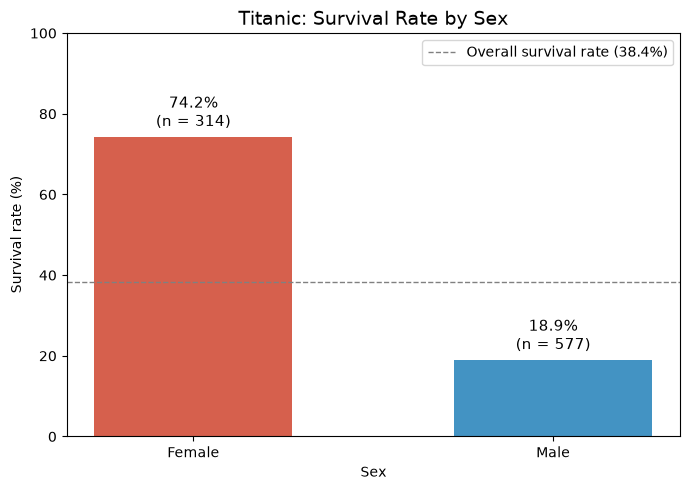

In [3]:
# Calculate survival rates by sex and visualize the comparison.

survival_by_sex = df.groupby("Sex")["Survived"].agg(
    passengers="count", survivors="sum", survival_rate="mean"
)
survival_by_sex["survival_rate_%"] = (survival_by_sex["survival_rate"] * 100).round(2)
display(survival_by_sex)

overall_rate = df["Survived"].mean() * 100

fig, ax = plt.subplots(figsize=(7, 5))
labels = ["Female", "Male"]
rates = survival_by_sex.loc[["female", "male"], "survival_rate_%"]
bars = ax.bar(labels, rates, color=["#d6604d", "#4393c3"], width=0.55)

for bar, rate, n in zip(bars, rates, survival_by_sex.loc[["female", "male"], "passengers"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.5,
            f"{rate:.1f}%\n(n = {n})", ha="center", va="bottom", fontsize=11)

ax.axhline(overall_rate, color="gray", linestyle="--", linewidth=1,
           label=f"Overall survival rate ({overall_rate:.1f}%)")
ax.set_title("Titanic: Survival Rate by Sex", fontsize=14)
ax.set_xlabel("Sex")
ax.set_ylabel("Survival rate (%)")
ax.set_ylim(0, 100)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

**Interpretation:** Which sex had the higher survival rate? Support your conclusion with the rates shown in your output.

**Women had a much higher survival rate.** Of the 314 female passengers, 233 survived, a survival rate of **74.20%**. Of the 577 male passengers, only 109 survived, a rate of **18.89%**. Women were therefore about **3.9 times more likely to survive** than men (74.20 / 18.89 ≈ 3.93), and both rates are far from the overall rate of 38.38% (women well above, men well below). The data support **Hypothesis 1**. This is consistent with the "women and children first" protocol applied when loading the lifeboats.

#### Hypothesis 2: First-class passengers were more likely to survive

Calculate the survival rate for each passenger class and create a clearly labeled chart to compare them.

,passengers,survivors,survival_rate,survival_rate_%
Pclass,,,,
1,216,136,0.629630,62.96
2,184,87,0.472826,47.28
3,491,119,0.242363,24.24


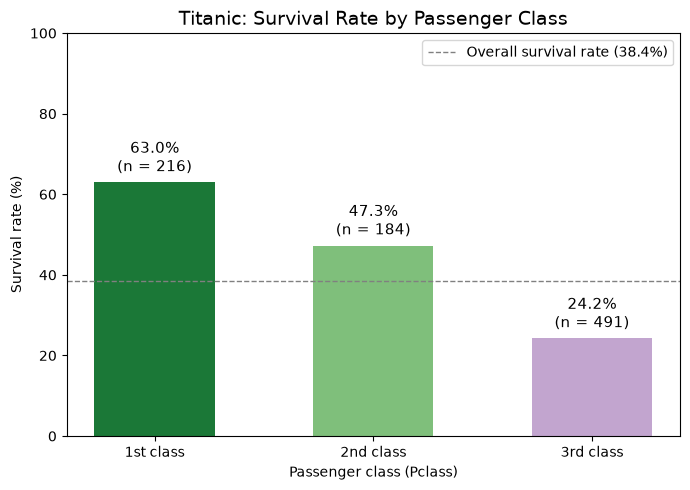

In [4]:
# Calculate survival rates by passenger class and visualize the comparison.

survival_by_class = df.groupby("Pclass")["Survived"].agg(
    passengers="count", survivors="sum", survival_rate="mean"
)
survival_by_class["survival_rate_%"] = (survival_by_class["survival_rate"] * 100).round(2)
display(survival_by_class)

fig, ax = plt.subplots(figsize=(7, 5))
labels = ["1st class", "2nd class", "3rd class"]
rates = survival_by_class["survival_rate_%"]
bars = ax.bar(labels, rates, color=["#1b7837", "#7fbf7b", "#c2a5cf"], width=0.55)

for bar, rate, n in zip(bars, rates, survival_by_class["passengers"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.5,
            f"{rate:.1f}%\n(n = {n})", ha="center", va="bottom", fontsize=11)

ax.axhline(overall_rate, color="gray", linestyle="--", linewidth=1,
           label=f"Overall survival rate ({overall_rate:.1f}%)")
ax.set_title("Titanic: Survival Rate by Passenger Class", fontsize=14)
ax.set_xlabel("Passenger class (Pclass)")
ax.set_ylabel("Survival rate (%)")
ax.set_ylim(0, 100)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

**Interpretation:** Which passenger class had the highest survival rate? Support your conclusion with the rates shown in your output.

**First class had the highest survival rate.** In first class, 136 of 216 passengers survived (**62.96%**); in second class, 87 of 184 (**47.28%**); and in third class, only 119 of 491 (**24.24%**). The survival rate decreases steadily as the class goes down, and a first-class passenger was about **2.6 times more likely to survive** than a third-class passenger (62.96 / 24.24 ≈ 2.60). Only first class is above the overall rate of 38.38%. The data support **Hypothesis 2**. A likely explanation is that first-class cabins were on the upper decks, closer to the lifeboats, while third class was on the lower decks and was also the largest group (491 passengers, more than half of everyone aboard).

### Assessment Rubric (10 points)

<table style="border-collapse: collapse; border-top: 1px solid; border-bottom: 1px solid;">
  <tr style="border-bottom: 1px solid;"><th style="border-left: none; border-right: none;" align="left">Criterion</th><th style="border-left: none; border-right: none;" align="right">Points</th></tr>
  <tr><td style="border-left: none; border-right: none;">Data inspection: required outputs and notes</td><td style="border-left: none; border-right: none;" align="right">2</td></tr>
  <tr><td style="border-left: none; border-right: none;">Hypothesis 1: survival rates by sex with a labeled chart (3); interpretation (1)</td><td style="border-left: none; border-right: none;" align="right">4</td></tr>
  <tr><td style="border-left: none; border-right: none;">Hypothesis 2: survival rates by class with a labeled chart (3); interpretation (1)</td><td style="border-left: none; border-right: none;" align="right">4</td></tr>
  <tr><td style="border-left: none; border-right: none;"><strong>Total</strong></td><td style="border-left: none; border-right: none;" align="right"><strong>10</strong></td></tr>
</table>